<a href="https://colab.research.google.com/github/ShubhamCode01/bank-telemarketing-ml/blob/main/ML_Paper.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, export_text
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import VotingClassifier
from sklearn.svm import SVC
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.inspection import permutation_importance
import warnings, os
warnings.filterwarnings("ignore")
os.environ["PYTHONWARNINGS"] = "ignore"
trap = getattr(np, "trapezoid", None) or np.trapz

df = pd.read_csv("bank-additional-full.csv", sep=";")
print(df.shape)
print(df["y"].value_counts(), "\nSuccess rate: %.2f%%" % (100 * (df.y == "yes").mean()))

# remove leakage (duration is known only after the call) and recode pdays (999 = never contacted)
df = df.drop(columns=["duration"])
df["pdays_contacted"] = (df["pdays"] != 999).astype(int)
df.loc[df["pdays"] == 999, "pdays"] = 0

y = (df["y"] == "yes").astype(int).values
X = df.drop(columns=["y"])
n = len(X); n_test = int(0.2 * n)          # newest 20% = test set (time ordered split)
X_tr, y_tr = X.iloc[:n - n_test], y[:n - n_test]
print("train:", len(X_tr), " test:", n_test)
df.head();

(41188, 21)
y
no     36548
yes     4640
Name: count, dtype: int64 
Success rate: 11.27%
train: 32951  test: 8237


In [ ]:
GROUPS = {   # business factors, analogue of the paper's Table 1
    "client":       ["age", "job", "marital", "education", "default", "housing", "loan"],
    "call_context": ["contact", "month", "day_of_week"],
    "history":      ["campaign", "pdays", "pdays_contacted", "previous", "poutcome"],
    "socio_econ":   ["emp.var.rate", "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed"],
}
ALL = [c for g in GROUPS.values() for c in g]

def make_pre(cols):
    cat = [c for c in cols if not pd.api.types.is_numeric_dtype(X[c])]
    num = [c for c in cols if c not in cat]
    return ColumnTransformer([("num", StandardScaler(), num),
                              ("cat", OneHotEncoder(handle_unknown="ignore"), cat)])

def make_model(name, cols, gamma=2 ** -7.8, seed=0):
    if name == "LR":
        clf = LogisticRegression(max_iter=1000)
    elif name == "DT":
        clf = DecisionTreeClassifier(min_samples_leaf=20, ccp_alpha=1e-4, random_state=seed)
    elif name == "NN":     # ensemble of Nr=7 networks, H=6 hidden nodes, probabilities averaged
        clf = VotingClassifier([(f"n{i}", MLPClassifier((6,), solver="lbfgs", max_iter=100,
                                random_state=seed * 10 + i)) for i in range(7)], voting="soft")
    elif name == "SVM":
        clf = SVC(kernel="rbf", C=3, gamma=gamma)
    return Pipeline([("pre", make_pre(cols)), ("clf", clf)])

def score(m, Xt):
    return m.predict_proba(Xt)[:, 1] if hasattr(m, "predict_proba") else m.decision_function(Xt)

def lift_curve(yt, s):
    o = np.argsort(-s)
    return np.arange(1, len(yt) + 1) / len(yt), np.cumsum(yt[o]) / yt.sum()

def alift(yt, s):
    x, c = lift_curve(yt, s)
    return trap(np.r_[0, c], np.r_[0, x])

def holdout_auc(cols, R=3, model="NN"):
    out = []
    for r in range(R):
        a, b, ya, yb = train_test_split(X_tr[cols], y_tr, test_size=1/3, random_state=r)
        out.append(roc_auc_score(yb, score(make_model(model, cols, seed=r).fit(a, ya), b)))
    return np.mean(out)

In [ ]:
print("Single-factor AUC (hypothesis test, threshold T2 = 0.65 in the paper):")
for g, cols in GROUPS.items():
    print(f"  {g:13s} AUC = {holdout_auc(cols, R=2, model='LR'):.4f}")

print("\nForward selection over confirmed factors (keep factor only if AUC improves):")
selected, best, chosen, table2 = [], 0, [], []
for g, cols in GROUPS.items():
    auc = holdout_auc(selected + cols, R=3, model="NN")
    keep = auc > best
    print(f"  + {g:13s} AUC = {auc:.4f}  -> {'kept' if keep else 'discarded'}")
    if keep:
        selected, best = selected + cols, auc
        chosen.append(g); table2.append((g, len(selected), round(auc, 4)))
SELECTED = selected
print("\nFinal features:", SELECTED)
pd.DataFrame(table2, columns=["factor added", "#features so far", "AUC"])

Single-factor AUC (hypothesis test, threshold T2 = 0.65 in the paper):
  client        AUC = 0.5725
  call_context  AUC = 0.6555
  history       AUC = 0.5357
  socio_econ    AUC = 0.6391

Forward selection over confirmed factors (keep factor only if AUC improves):
  + client        AUC = 0.5777  -> kept
  + call_context  AUC = 0.6649  -> kept
  + history       AUC = 0.6705  -> kept
  + socio_econ    AUC = 0.6719  -> kept

Final features: ['age', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'campaign', 'pdays', 'pdays_contacted', 'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']


,factor added,#features so far,AUC
0,client,7,0.5777
1,call_context,10,0.6649
2,history,15,0.6705
3,socio_econ,20,0.6719


In [ ]:
R = 5   # paper used 20
runs = {m: {"AUC": [], "ALIFT": []} for m in ["LR", "DT", "NN", "SVM"]}
for r in range(R):
    a, b, ya, yb = train_test_split(X_tr[SELECTED], y_tr, test_size=1/3, random_state=r)
    for m in runs:
        s = score(make_model(m, SELECTED, seed=r).fit(a, ya), b)
        runs[m]["AUC"].append(roc_auc_score(yb, s)); runs[m]["ALIFT"].append(alift(yb, s))
table3 = pd.DataFrame({m: {k: np.mean(v) for k, v in d.items()} for m, d in runs.items()}).round(3)
print(table3)
print("\nMann-Whitney p-values, NN vs others (AUC):")
for m in ["LR", "DT", "SVM"]:
    print(f"  NN vs {m}: p = {mannwhitneyu(runs['NN']['AUC'], runs[m]['AUC']).pvalue:.4f}")

          LR     DT     NN    SVM
AUC    0.666  0.665  0.672  0.567
ALIFT  0.656  0.657  0.661  0.563

Mann-Whitney p-values, NN vs others (AUC):
  NN vs LR: p = 0.4206
  NN vs DT: p = 0.5476
  NN vs SVM: p = 0.0079


In [ ]:
import time
rows = []
t = time.time(); auc_all = holdout_auc(ALL, R=2, model="NN")
rows.append(("no selection", len(ALL), round(time.time() - t), round(auc_all, 4)))

t = time.time()                      # standard forward selection (LR used for speed; paper used NN)
sel, best = [], 0
while True:
    cand = {c: holdout_auc(sel + [c], R=1, model="LR") for c in ALL if c not in sel}
    if not cand: break
    c, a = max(cand.items(), key=lambda kv: kv[1])
    if a <= best: break
    sel.append(c); best = a
rows.append(("forward selection (LR)", len(sel), round(time.time() - t), round(best, 4)))

t = time.time(); auc_prop = holdout_auc(SELECTED, R=2, model="NN")
rows.append(("proposed (factor + forward)", len(SELECTED), round(time.time() - t), round(auc_prop, 4)))
pd.DataFrame(rows, columns=["method", "#features", "time (s)", "AUC"])

,method,#features,time (s),AUC
0,no selection,20,41,0.6709
1,forward selection (LR),12,43,0.6915
2,proposed (factor + forward),20,37,0.6709


In [ ]:
W, K = 20000, 500        # paper: W=20000, K=10 (slow). Lower K for closer replication.
def rolling_window(name):
    ys, ss = [], []
    for i in range(n - n_test, n, K):
        tr, te = slice(i - W, i), slice(i, min(i + K, n))
        m = make_model(name, SELECTED).fit(X.iloc[tr][SELECTED], y[tr])
        ss.append(score(m, X.iloc[te][SELECTED])); ys.append(y[te])
    return np.concatenate(ys), np.concatenate(ss)

curves, res = {}, {}
for name in ["LR", "DT", "SVM", "NN"]:
    yt, s = rolling_window(name); curves[name] = (yt, s)
    res[name] = {"AUC": roc_auc_score(yt, s), "ALIFT": alift(yt, s)}
table5 = pd.DataFrame(res).round(3); print(table5)

          LR     DT    SVM     NN
AUC    0.731  0.756  0.708  0.765
ALIFT  0.659  0.678  0.644  0.683


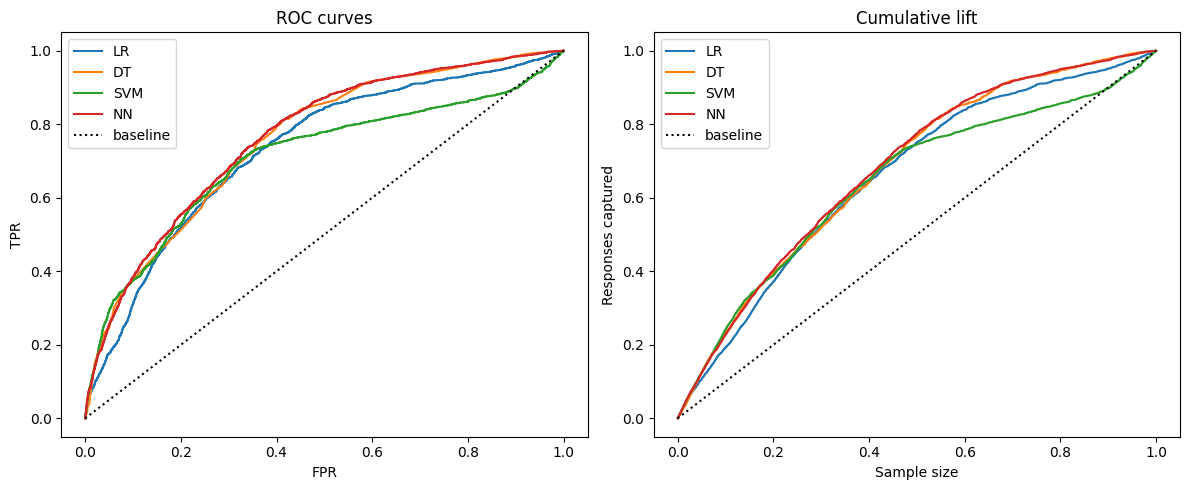

         LR     DT    SVM     NN
10%   0.193  0.233  0.242  0.227
20%   0.372  0.396  0.388  0.402
30%   0.522  0.519  0.527  0.542
40%   0.643  0.643  0.648  0.660
50%   0.751  0.767  0.745  0.775
60%   0.839  0.854  0.785  0.863
70%   0.884  0.919  0.822  0.917
80%   0.921  0.946  0.857  0.950
90%   0.951  0.977  0.898  0.974
100%  1.000  1.000  1.000  1.000

NN: contacting the best 50% of clients captures 77.5% of subscribers (paper: 79% vs 50% random)


In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
for name, (yt, s) in curves.items():
    f, t_, _ = roc_curve(yt, s); ax[0].plot(f, t_, label=name)
    x, c = lift_curve(yt, s);    ax[1].plot(x, c, label=name)
for a_, ttl, xl, yl in zip(ax, ["ROC curves", "Cumulative lift"],
                           ["FPR", "Sample size"], ["TPR", "Responses captured"]):
    a_.plot([0, 1], [0, 1], "k:", label="baseline"); a_.set(title=ttl, xlabel=xl, ylabel=yl); a_.legend()
plt.tight_layout(); plt.savefig("fig_roc_lift.png", dpi=150); plt.show()

sizes = [.1, .2, .3, .4, .5, .6, .7, .8, .9, 1.0]
lt = {m: [lift_curve(*curves[m])[1][int(p * len(curves[m][0])) - 1] for p in sizes] for m in curves}
lift_table = pd.DataFrame(lt, index=[f"{int(p*100)}%" for p in sizes]).round(3)
print(lift_table)
print(f"\nNN: contacting the best 50% of clients captures {lift_table.loc['50%','NN']:.1%} of subscribers"
      " (paper: 79% vs 50% random)")

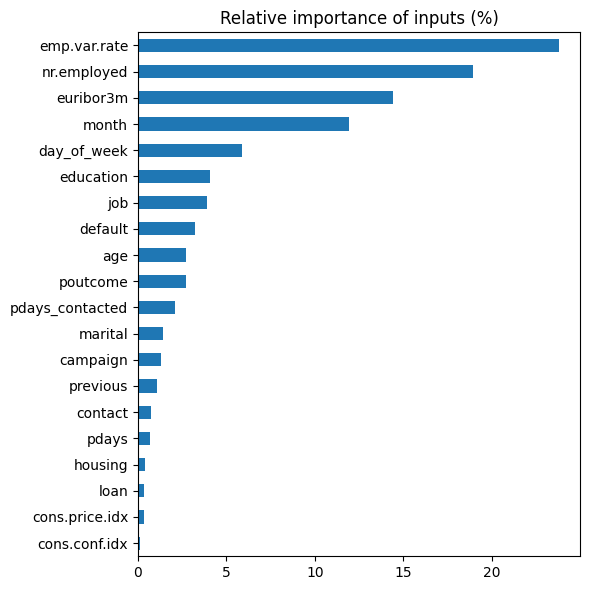

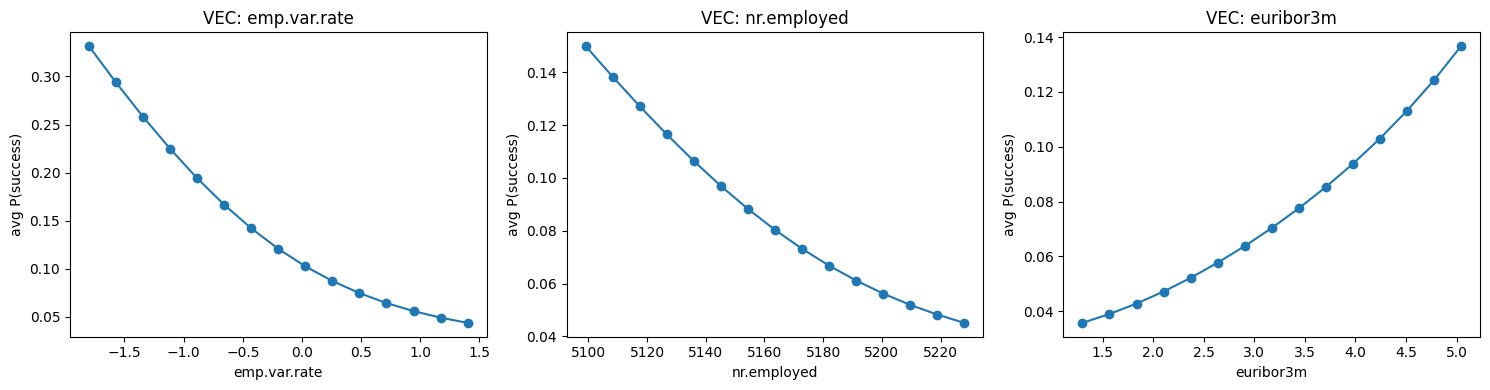

Surrogate tree MAE vs NN: 0.014
|--- num__cons.conf.idx <= -1.55
|   |--- num__euribor3m <= -2.14
|   |   |--- num__euribor3m <= -2.24
|   |   |   |--- cat__poutcome_success <= 0.50
|   |   |   |   |--- num__age <= -0.91
|   |   |   |   |   |--- value: [0.36]
|   |   |   |   |--- num__age >  -0.91
|   |   |   |   |   |--- num__age <= 2.08
|   |   |   |   |   |   |--- value: [0.25]
|   |   |   |   |   |--- num__age >  2.08
|   |   |   |   |   |   |--- value: [0.38]
|   |   |   |--- cat__poutcome_success >  0.50
|   |   |   |   |--- value: [0.57]
|   |   |--- num__euribor3m >  -2.24
|   |   |   |--- num__euribor3m <= -2.23
|   |   |   |   |--- cat__day_of_week_tue <= 0.50
|   |   |   |   |   |--- cat__day_of_week_wed <= 0.50
|   |   |   |   |   |   |--- value: [0.10]
|   |   |   |   |   |--- cat__day_of_week_wed >  0.50
|   |   |   |   |   |   |--- value: [0.32]
|   |   |   |   |--- cat__day_of_week_tue >  0.50
|   |   |   |   |   |--- value: [0.35]
|   |   |   |--- num__euribor3m >  -2.

In [ ]:
nn = make_model("NN", SELECTED).fit(X_tr[SELECTED], y_tr)

# 8a) input importance (permutation importance as a stand-in for the paper's DSA)
pi = permutation_importance(nn, X_tr[SELECTED].iloc[-8000:], y_tr[-8000:],
                            scoring="roc_auc", n_repeats=5, random_state=0)
imp = pd.Series(pi.importances_mean, index=SELECTED).clip(lower=0)
imp = (100 * imp / imp.sum()).sort_values()
imp.plot.barh(figsize=(6, 6), title="Relative importance of inputs (%)")
plt.tight_layout(); plt.savefig("fig_importance.png", dpi=150); plt.show()

# 8b) VEC-style curves for top numeric inputs
top_num = [c for c in imp.index[::-1] if pd.api.types.is_numeric_dtype(X[c])][:3]
sample = X_tr[SELECTED].sample(2000, random_state=0)
fig, ax = plt.subplots(1, len(top_num), figsize=(5 * len(top_num), 4))
for a_, c in zip(np.atleast_1d(ax), top_num):
    grid = np.linspace(X_tr[c].min(), X_tr[c].max(), 15); v = []
    for g in grid:
        tmp = sample.copy(); tmp[c] = g; v.append(score(nn, tmp).mean())
    a_.plot(grid, v, "o-"); a_.set(xlabel=c, ylabel="avg P(success)", title=f"VEC: {c}")
plt.tight_layout(); plt.savefig("fig_vec.png", dpi=150); plt.show()

# 8c) rule extraction: decision tree learns the NN outputs (paper Fig. 5)
p_nn = nn.predict_proba(X_tr[SELECTED])[:, 1]
Z = nn.named_steps["pre"].transform(X_tr[SELECTED]); names = nn.named_steps["pre"].get_feature_names_out()
tree = DecisionTreeRegressor(max_depth=6, ccp_alpha=1e-5, random_state=0).fit(Z, p_nn)
print("Surrogate tree MAE vs NN: %.3f" % np.abs(tree.predict(Z) - p_nn).mean())
print(export_text(tree, feature_names=list(names), max_depth=6))

MAE vs NN: 0.014  (paper: 0.03)


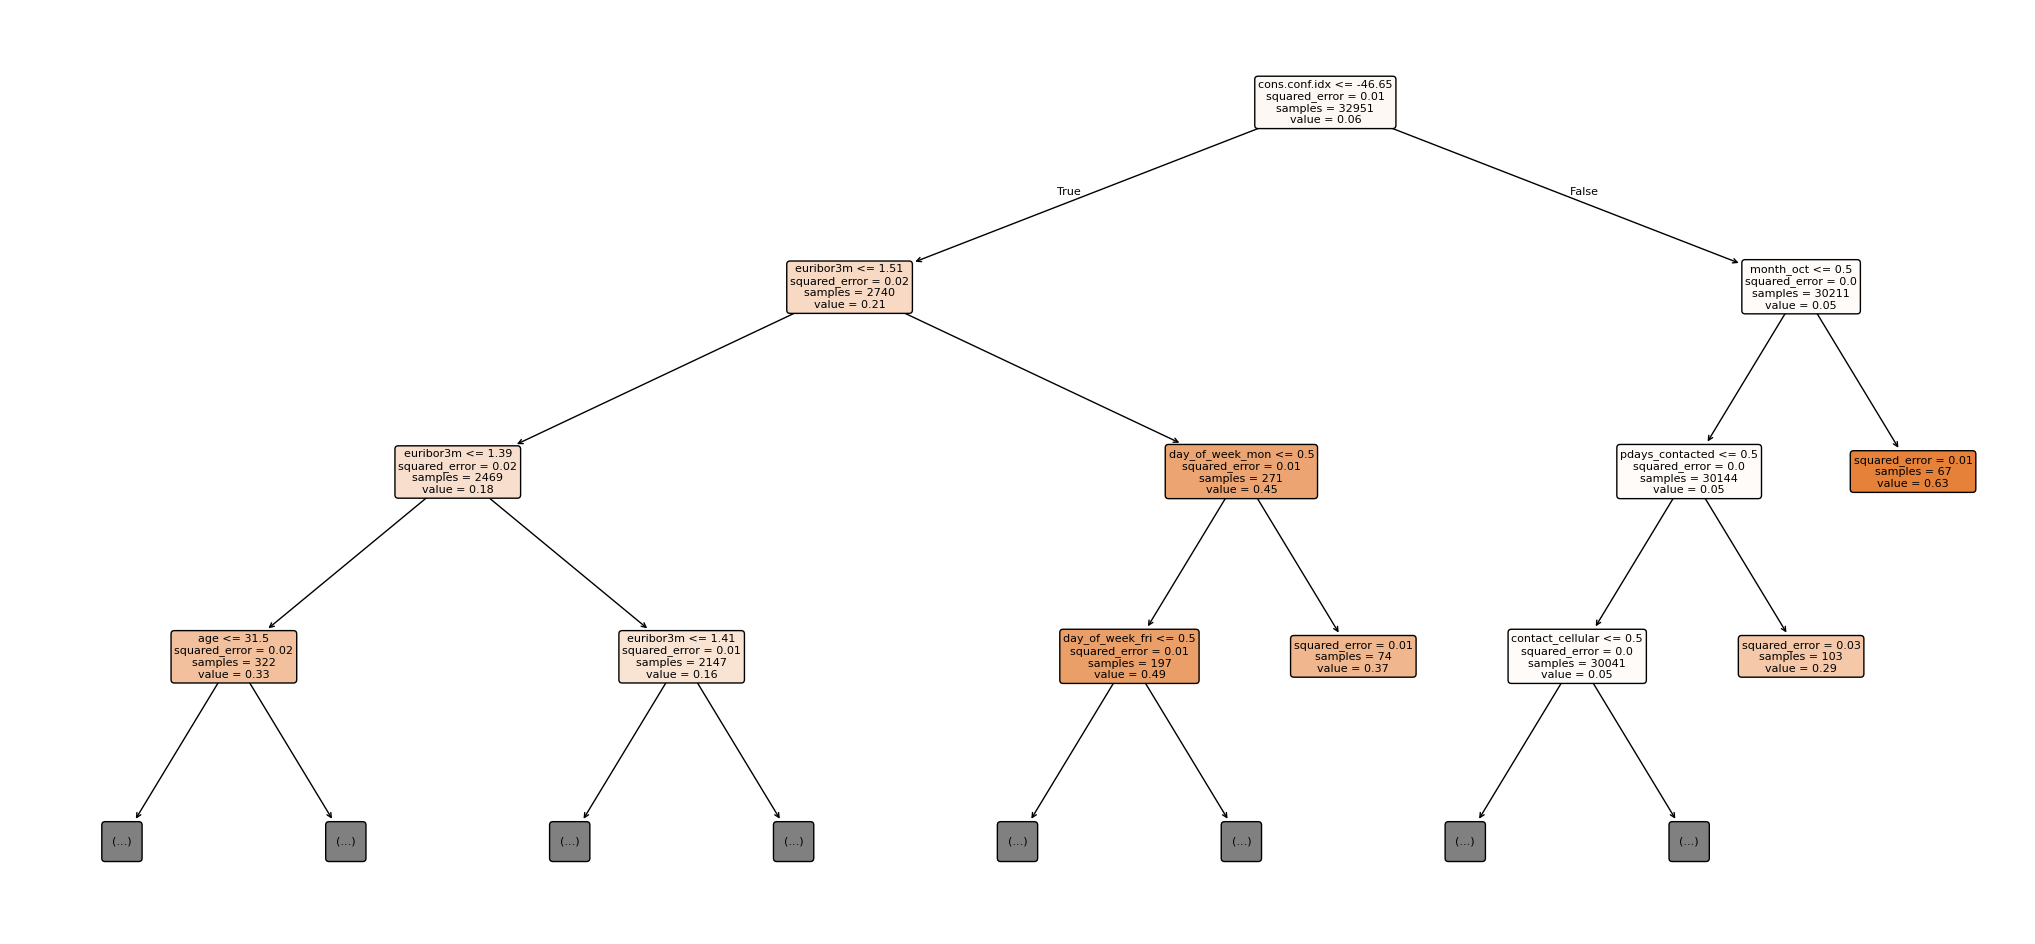

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeRegressor, plot_tree

cat = [c for c in SELECTED if not pd.api.types.is_numeric_dtype(X[c])]
num = [c for c in SELECTED if c not in cat]
raw_pre = ColumnTransformer([("num", "passthrough", num),
                             ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat)])
Z_raw = raw_pre.fit_transform(X_tr[SELECTED])
names_raw = [n.replace("num__", "").replace("cat__", "") for n in raw_pre.get_feature_names_out()]

tree = DecisionTreeRegressor(max_depth=6, min_samples_leaf=50, ccp_alpha=0.001**2, random_state=0)
tree.fit(Z_raw, p_nn)
print("MAE vs NN: %.3f  (paper: 0.03)" % np.abs(tree.predict(Z_raw) - p_nn).mean())

plt.figure(figsize=(26, 12))
plot_tree(tree, feature_names=names_raw, max_depth=3, filled=True, rounded=True, fontsize=8, precision=2)
plt.savefig("fig_extracted_tree_raw.png", dpi=150, bbox_inches="tight"); plt.show()

In [ ]:
import time, warnings
warnings.filterwarnings("ignore")

W, K = 20000, 500          # window size, predictions per update (paper: W=20000, K=10)
models = ["LR", "DT", "SVM", "NN"]
records, all_pred = [], {m: ([], []) for m in models}

for u, i in enumerate(range(n - n_test, n, K), start=1):
    tr, te = slice(i - W, i), slice(i, min(i + K, n))
    y_te = y[te]
    for m in models:
        t = time.time()
        mdl = make_model(m, SELECTED).fit(X.iloc[tr][SELECTED], y[tr])
        s = score(mdl, X.iloc[te][SELECTED])
        all_pred[m][0].append(y_te); all_pred[m][1].append(s)
        ok = 0 < y_te.sum() < len(y_te)            # AUC needs both classes in the window
        records.append({"update": u, "model": m, "success_rate": y_te.mean(),
                        "AUC": roc_auc_score(y_te, s) if ok else np.nan,
                        "ALIFT": alift(y_te, s) if ok else np.nan})
    print(f"update {u} done")

win = pd.DataFrame(records)

# cumulative (expanding) AUC: quality of ALL predictions made up to each update
cum = {}
for m in models:
    ys, ss = all_pred[m]
    cum[m] = [roc_auc_score(np.concatenate(ys[:k]), np.concatenate(ss[:k]))
              for k in range(1, len(ys) + 1)]

fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
for m in models:
    d = win[win.model == m]
    ax[0].plot(d["update"], d["AUC"], "o-", label=m)
    ax[1].plot(range(1, len(cum[m]) + 1), cum[m], label=m)
ax[0].set(title="AUC per window (each update's K predictions)", xlabel="update", ylabel="AUC")
ax[1].set(title="Cumulative AUC up to each update", xlabel="update", ylabel="AUC")
sr = win[win.model == "NN"]
ax[2].bar(sr["update"], sr["success_rate"]); ax[2].set(title="Real success rate in each window",
                                                      xlabel="update", ylabel="share of subscribers")
for a_ in ax[:2]: a_.legend(); a_.grid(alpha=.3)
plt.tight_layout(); plt.savefig("fig_rolling_windows.png", dpi=150); plt.show()

print(win.pivot(index="update", columns="model", values="AUC").round(3))
print("\nMean / std of per-window AUC:")
print(win.groupby("model")["AUC"].agg(["mean", "std", "min", "max"]).round(3))

update 1 done
update 2 done
update 3 done
update 4 done
update 5 done
update 6 done
update 7 done
update 8 done
update 9 done
update 10 done
update 11 done
update 12 done
update 13 done
update 14 done
